# The Philosophy of Uncertainty
In this notebook, I aim to navigate chapter 2.3 of Bishop's *Pattern Recognition and Machine Learning* textbook to form a narrative contrasting the Frequentist point-estimate flaw with the Bayesian preservation of uncertainty.

In [29]:
import jax
import jax.numpy as jnp
import jax.scipy.stats as stats
import matplotlib.pyplot as plt

## Part 1: The Frequentist Flaw — Bias of the Variance (Section 2.3.4)

In this section, we will prove empirically that the ML variance systematically underestimates the true variance for small datasets because it relies on a fitted mean rather than the true mean.

In [11]:
# Step 1: Setup and Ground Truth
root_key = jax.random.PRNGKey(24)

mu_true = 0.0
sig2_true = 1.0
sig_true = jnp.sqrt(sig2_true)

N = 5 # dataset size
K = 10000 # simulation size

In [12]:
# Step 2: Parallel Data Generation
standard_samples = jax.random.normal(root_key, shape=(K, N))

datasets = mu_true + (sig_true * standard_samples)

# Verification
print(f"Shape of the dataset matrix: {datasets.shape}")

print(f"First simulated dataset of 5 points: {datasets[0]}")

Shape of the dataset matrix: (10000, 5)
First simulated dataset of 5 points: [ 0.36450562 -0.27789226 -0.5182374   0.6295778  -1.1161703 ]


In [13]:
# Step 3: Vectorized Maximum Likelihood Estimation
def compute_ml_params(dataset):
    mu_ml = jnp.mean(dataset)
    sig2_ml = jnp.var(dataset)
    return mu_ml, sig2_ml

vectorized_compute_ml = jax.vmap(compute_ml_params)

mu_ml_estimates, sig2_ml_estimates = vectorized_compute_ml(datasets)

print(f"Shape of ML Means array: {mu_ml_estimates.shape}")
print(f"Shape of ML Variance array: {sig2_ml_estimates.shape}")

Shape of ML Means array: (10000,)
Shape of ML Variance array: (10000,)


In [ ]:
# Step 4: Evaluation and Visualization
sig2_ml_avg = jnp.mean(sig2_ml_estimates)

print(f"True Population Variance: {sig2_true}")
print(f"Expected ML Variance (Eq 2.122): {sig2_true * (N - 1) / N}")
print(f"Empirical Average ML Variance: {sig2_ml_avg:.4f}")

True Population Variance: 1.0
Expected ML Variance (Eq 2.122): 0.8
Empirical Average ML Variance: 0.8027


We can examine that the empirical expected variance is lower than that of the true variance, 1.0. 

<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:11: SyntaxWarning: invalid escape sequence '\s'
<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:11: SyntaxWarning: invalid escape sequence '\s'
/var/folders/mr/gyhq4nd5159cfdvmmd1l_d440000gn/T/ipykernel_57233/2392390931.py:5: SyntaxWarning: invalid escape sequence '\s'
  color='steelblue', edgecolor='black', label='Distribution of $\sigma^2{ML}$')
/var/folders/mr/gyhq4nd5159cfdvmmd1l_d440000gn/T/ipykernel_57233/2392390931.py:8: SyntaxWarning: invalid escape sequence '\s'
  label=f'True Variance ($\sigma^2 = {sig2_true}$)')
/var/folders/mr/gyhq4nd5159cfdvmmd1l_d440000gn/T/ipykernel_57233/2392390931.py:11: SyntaxWarning: invalid escape sequence '\s'
  label=f'Average ML Variance ($\sim {sig2_ml_avg:.2f}$)')


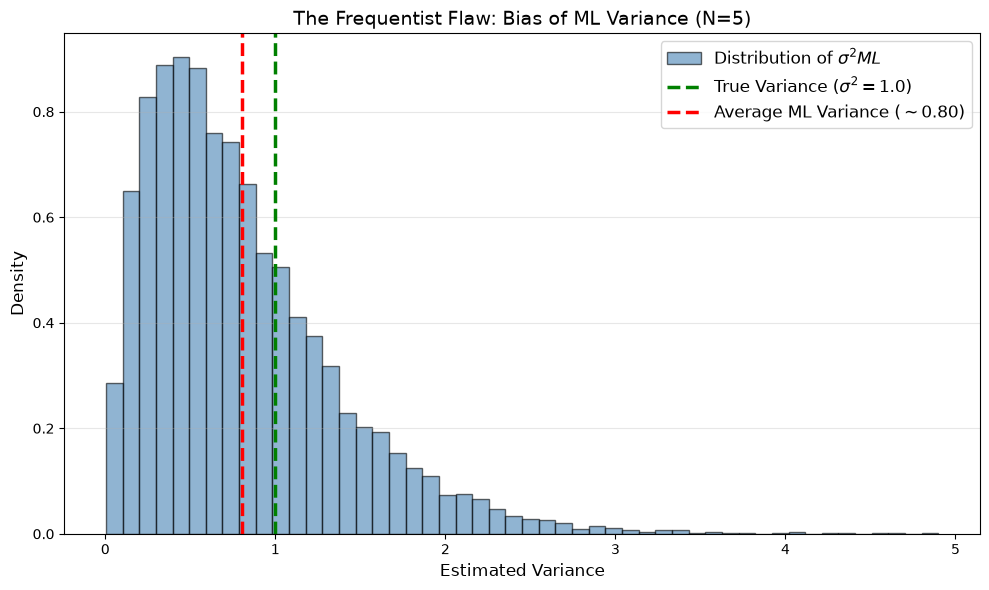

In [18]:
plt.figure(figsize=(10, 6))

# Plot the histogram of the 10,000 estimates
plt.hist(sig2_ml_estimates, bins=50, density=True, alpha=0.6,
        color='steelblue', edgecolor='black', label='Distribution of $\sigma^2{ML}$')

plt.axvline(sig2_true, color='green', linestyle='dashed', linewidth=2.5, 
            label=f'True Variance ($\sigma^2 = {sig2_true}$)')

plt.axvline(sig2_ml_avg, color='red', linestyle='dashed', linewidth=2.5, 
            label=f'Average ML Variance ($\sim {sig2_ml_avg:.2f}$)')

plt.title(f'The Frequentist Flaw: Bias of ML Variance (N={N})', fontsize=14)
plt.xlabel('Estimated Variance', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend(fontsize=12)
plt.grid(axis='y', alpha=0.3)

# Show the plot
plt.tight_layout()
plt.show()

The distribution is right-skewed. Most of the ML estimates fall to the left of the true variance(green dotted line). Hence the simulation empirically reveals that because ML approach fits the mean to the specific noise of the small ($N=5$) sample, it artificially reduces the spread, causing it to systematically underestimate the true uncertainty of the universe it is trying to model.

Bessel's correction works to address this systematic bias of a 1D Gaussian, but it's effectiveness is limited in two folds.
1. It is a post-hoc patch and relies on a separate mathematical proof to manually adjust it. It does not scale to arbitrary complex models like a mixture model, a Gaussian process, or a neural network. 
2. An "Unbiased Point Estimate" is, after all, a Point Estimate. Even if we could magically find unbiased estimates for all models, frequentist approach forces us to collapse all of the information and knowledge onto a single point. By committing to these single values, the model acts as if it is 100% certain that these are the true parameters of the universe, simply because they are unbiased. But "unbiased" just means "correct on average if we repeated this experiment infinitely." It does not mean you have the correct parameters for this specific small dataset.

## Part 2: The Bayesian Approach: Sequential Update of the Mean

In this section, we assume the variance is known and update our belief about the mean one data point at a time. 

In [26]:
# Step 1: Setup Prior and True Distribution
mu_true = 0.8
sig2_data = 0.1

mu_0 = 0.0
sig2_0 = 0.1

dataset = mu_true + jnp.sqrt(sig2_data) * jax.random.normal(root_key, shape=(50,))

In [27]:
# Step 2: Define the Bayesian Update Step
def update_posterior(carry, new_data_point):
    """
    Args:
        carry: contains the current state of our belief (current_mu, current_sig2)
        new_data_point: is a single scalar xi
    
    Returns:
        (mu_new, sig2_new), (mu_new, sig2_new): The first tuple updates the carry, the second saves the history
    """
    current_mu, current_sig2 = carry

    new_precision = (1.0 / current_sig2) + (1.0 / sig2_data)
    sig2_new = 1.0 / new_precision

    mu_new = sig2_new * ((current_mu / current_sig2) + (new_data_point / sig2_data))

    new_carry = (mu_new, sig2_new)

    return new_carry, new_carry

In [28]:
# Step 3: Sequetial Processing with `scan`
init_carry = (mu_0, sig2_0)

final_state, history = jax.lax.scan(update_posterior, init_carry, dataset)

<>:37: SyntaxWarning: invalid escape sequence '\m'
<>:41: SyntaxWarning: invalid escape sequence '\m'
<>:42: SyntaxWarning: invalid escape sequence '\m'
<>:37: SyntaxWarning: invalid escape sequence '\m'
<>:41: SyntaxWarning: invalid escape sequence '\m'
<>:42: SyntaxWarning: invalid escape sequence '\m'
/var/folders/mr/gyhq4nd5159cfdvmmd1l_d440000gn/T/ipykernel_57233/1147477154.py:37: SyntaxWarning: invalid escape sequence '\m'
  label=f'True Mean ($\mu = {mu_true}$)')
/var/folders/mr/gyhq4nd5159cfdvmmd1l_d440000gn/T/ipykernel_57233/1147477154.py:41: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Hypothesized Mean ($\mu$)', fontsize=12)
/var/folders/mr/gyhq4nd5159cfdvmmd1l_d440000gn/T/ipykernel_57233/1147477154.py:42: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('Density $p(\mu | \mathcal{D})$', fontsize=12)


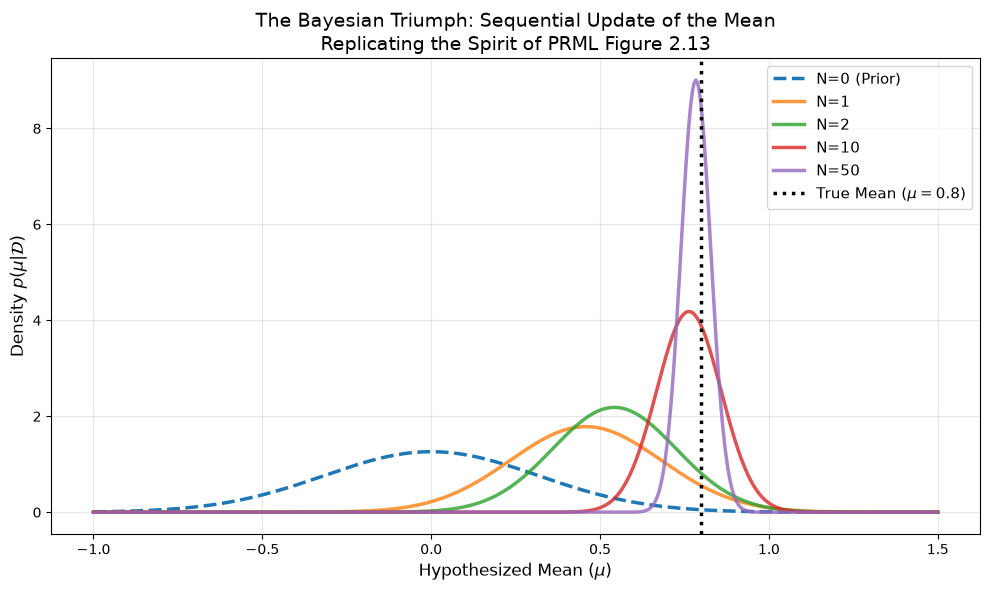

In [ ]:
mu_history, sig2_history = history
# 1. Define the grid of possible mean values to evaluate our PDFs over
x_grid = jnp.linspace(-1.0, 1.5, 500)

# 2. Define the specific checkpoints we want to visualize
# N=0 is our Prior. The others are data points processed.
checkpoints = [0, 1, 2, 10, 50]

plt.figure(figsize=(10, 6))

# 3. Iterate through our checkpoints and plot the distribution for each
for n in checkpoints:
    if n == 0:
        # The Prior (Before seeing any data)
        current_mu = mu_0
        current_sigma2 = sig2_0
        label = "N=0 (Prior)"
        linestyle = 'dashed'
        alpha = 1.0
    else:
        # The Posterior (After seeing 'n' data points)
        current_mu = mu_history[n - 1]
        current_sigma2 = sig2_history[n - 1]
        label = f"N={n}"
        linestyle = 'solid'
        alpha = 0.8 
        
    # Calculate the Gaussian PDF over the grid using JAX's stats module
    pdf_values = stats.norm.pdf(x_grid, loc=current_mu, scale=jnp.sqrt(current_sigma2))
    
    # Plot the curve
    plt.plot(x_grid, pdf_values, label=label, linestyle=linestyle, linewidth=2.5, alpha=alpha)

# 4. Add a vertical line to represent the absolute "Truth" of the universe
plt.axvline(mu_true, color='black', linestyle='dotted', linewidth=2.5, 
            label=f'True Mean ($\mu = {mu_true}$)')

# 5. Formatting
plt.title('The Bayesian Triumph: Sequential Update of the Mean\nReplicating the Spirit of PRML Figure 2.13', fontsize=14)
plt.xlabel('Hypothesized Mean ($\mu$)', fontsize=12)
plt.ylabel('Density $p(\mu | \mathcal{D})$', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='both', alpha=0.3)

plt.tight_layout()
plt.show()

Notice two things:
1. The peak of the curve shifts from 0.0 (prior assumption) toward 0.8 (the absolute truth) as N increases.
2. The width of the curve dramatically shrinks. The variance of the distribution represents the model's epistemic uncertainty. By $N=50$, the curve is incredibly narrow and tall, visually proving that the uncertainty has been dissolved by the overwhelming weight of the evidence. 